# 01 semeval2018 exploration

Aggregate exploration only. Run download and preprocessing first. Labels and annotation methods differ across datasets. Test examples are not used for model tuning or qualitative error analysis. Source terms and decisions: `../docs/DATASETS.md`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().resolve()
while not (root / 'src' / 'preprocess.py').exists():
    if root == root.parent:
        raise RuntimeError('Open this notebook inside the repository')
    root = root.parent
sys.path.insert(0, str(root))
from src.explore_data import explore, comparison


## Source and cleaning audit

`input` describes the loaded records before exclusions. For SARC this is the selected sample; full official partition counts are recorded separately. Missing raw fields, exact duplicates, normalized conflicts, near-duplicate pairs, removals and actual split percentages are reported separately. Missing optional annotation fields are not treated as negative annotations.

semeval2018
{
  "dataset": "semeval2018",
  "seed": 42,
  "metadata": {
    "annotation": "Manual fine-grained irony annotation",
    "task_b_codes": {
      "0": "non-ironic",
      "1": "verbal irony with polarity contrast",
      "2": "situational irony",
      "3": "other verbal irony"
    },
    "join": "One-to-one tweet index within partition and binary-label agreement verified. Training index 2305 has | versus literal backslash-n line separators; normalized wording verified, Task A text retained. All other texts match exactly.",
    "limitations": "Hashtag collection bias; subtype categories are not exact explicit/implicit incongruity labels."
  },
  "input": {
    "count": 4618,
    "negative": 2396,
    "positive": 2222,
    "positive_percent": 48.11606756171503,
    "mean_characters": 87.76050238198354,
    "median_characters": 89.0,
    "mean_words": 13.837158943265482,
    "context_count": 0,
    "irony_categories": [
      "0",
      "1",
      "2",
      "3"
    ]
  },
  

,count,negative,positive,positive_percent,mean_characters,median_characters,mean_words,context_count,irony_categories,csv_sha256
train,3067,1538,1529,49.853277,87.072383,88.0,13.749918,0,"[0, 1, 2, 3]",f1868b759be2a5ee8b26fbabf4a9d0d378f950ab53d664...
dev,767,385,382,49.804433,87.082138,89.0,13.645372,0,"[0, 1, 2, 3]",952397a44ffef78f1f2d827fa97479be7767583e151f5e...
test,784,473,311,39.668367,91.116071,93.0,14.366071,0,"[0, 1, 2, 3]",b463ed01f2c78464d72187de6548edcd8a2afd417892c0...


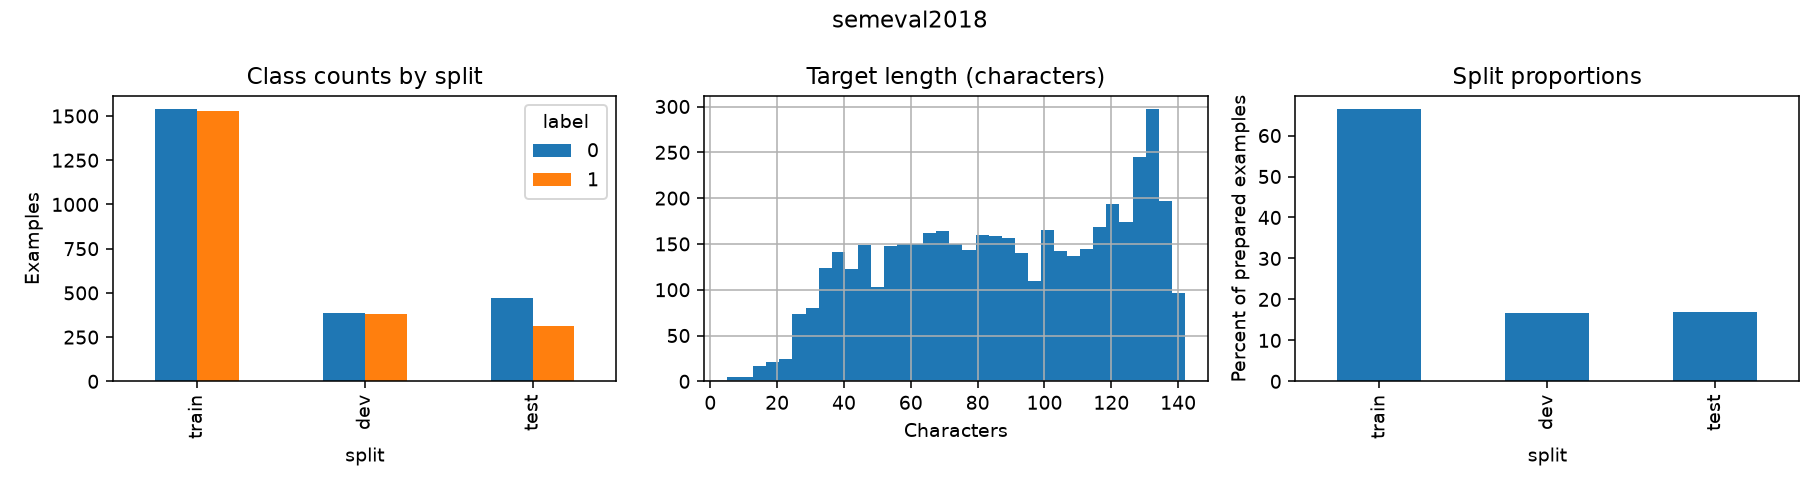

In [2]:
names = ['semeval2018']
for name in names:
    audit = explore(name)
    print(name)
    print(json.dumps({k:v for k,v in audit.items() if k != 'splits'}, indent=2))
    display(pd.DataFrame(audit['splits']).T)
    display(Image(filename=str(root / 'results' / 'figures' / (name.replace('/', '_') + '.png'))))

## Interpretation

Compare class percentages and actual split sizes. Check the removal audit before explaining performance differences. High scores on repetitive templates do not establish generalization to natural conversations. Context is a JSON list in chronological order; metadata such as author, rephrasing and label-derived subtypes must not become target-only model inputs.